# Простые модели и сезонное обучение

EGLL 09L, погожие дни 2025 года. Ridge, Huber, ElasticNet и Polynomial Ridge учат поправку к прогнозу с постоянной вертикальной скоростью. Горизонт 30 ± 3 секунды, девять прежних причинных признаков, наблюдения до барометрического прокси 300 ft. Меток ухода на второй круг здесь нет. QNH использует архивные COR METAR с условной задержкой 15 минут; фактическое время публикации исправлений неизвестно.

Последний выбранный день каждого сезона оставлен для теста, предыдущий для валидации, остальные для обучения. Идентификатор борта не является признаком; борта могут повторяться между днями. Параметры выбираются по валидации. Каждый заход имеет одинаковый суммарный обучающий вес

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
base = Path.cwd()
if not (base / 'scripts/table_style.py').is_file():
    base = base.parent
sys.path.insert(0, str(base / 'scripts'))
from table_style import display_table
days = pd.read_csv(base / 'reports/csv/selected_days.csv')
metrics = pd.read_csv(base / 'reports/csv/model_metrics.csv')
learning = pd.read_csv(base / 'reports/csv/learning_curve.csv')
table = pd.read_csv(base / 'reports/csv/final_table.csv', index_col=0)
season_labels = {'winter': 'Зима', 'spring': 'Весна', 'summer': 'Лето', 'autumn': 'Осень'}
seasons = [s for s in season_labels if s in table.columns]
labels = [season_labels[s] for s in seasons]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
display_table(display, days.groupby(['season', 'split']).agg(Дней=('day', 'size'),
             Заходов=('approaches', 'sum'), Пар=('examples', 'sum')))


## Итоговая таблица

Обучение на всех доступных обучающих днях выбранных сезонов. Ошибка MAE усредняется сначала внутри каждого захода, затем между заходами; единица измерения ft. Проверочные дни одинаковы для всех моделей

In [2]:
shown = table.rename(columns=dict(zip(seasons + ['all'], labels + ['Все сезоны'])))
display_table(display, shown.style.format('{:.2f}').highlight_min(axis=0, color='#B6E66B'))


,Весна,Лето,Осень,Все сезоны
model,,,,
Ridge,17.59,16.89,14.45,16.34
Polynomial Ridge,16.67,16.20,13.38,15.45
Huber,17.21,17.02,14.01,16.11
ElasticNet,17.34,17.04,14.24,16.24
Constant vertical rate,59.70,66.06,41.45,55.95


## Влияние числа дней

Четыре модели используют одни и те же проверочные дни при добавлении обучающих дней по порядку дат. Берем все пригодные примеры включенных дней. Это первое сравнение: одновременно растут число примеров и разнообразие дней. Параметры фиксируются после выбора по валидации полного обучающего набора сезона

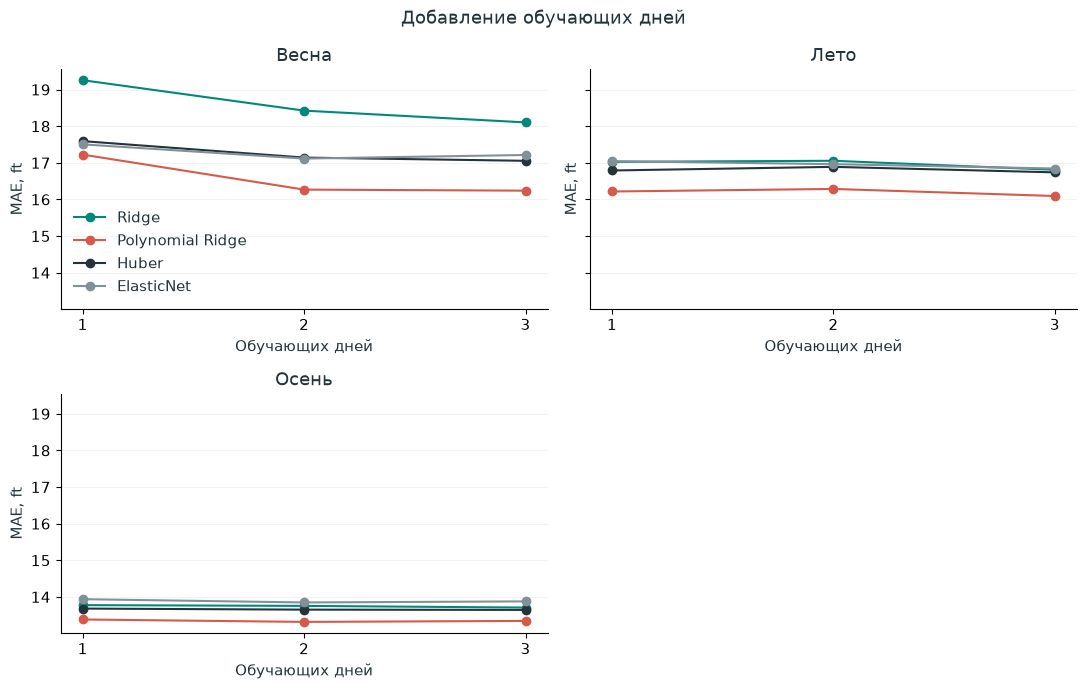

season,model,train_days,train_approaches,macro_mae_ft
spring,Ridge,1,384,19.26
spring,Polynomial Ridge,1,384,17.22
spring,Huber,1,384,17.59
spring,ElasticNet,1,384,17.50
spring,Ridge,2,774,18.42
spring,Polynomial Ridge,2,774,16.27
spring,Huber,2,774,17.14
spring,ElasticNet,2,774,17.12
spring,Ridge,3,1136,18.10
spring,Polynomial Ridge,3,1136,16.24


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, season, label in zip(axes.flat, seasons, labels):
    subset = learning.loc[learning.season.eq(season) & learning.converged]
    for model, color in [('Ridge', '#00897B'), ('Polynomial Ridge', '#D65A4A'),
                         ('Huber', '#25343B'), ('ElasticNet', '#829198')]:
        values = subset.loc[subset.model.eq(model)].sort_values('train_days')
        ax.plot(values.train_days, values.macro_mae_ft, marker='o', color=color, label=model)
    ax.set(title=label, xlabel='Обучающих дней', ylabel='MAE, ft')
    ax.set_xticks(sorted(subset.train_days.unique()))
    ax.grid(axis='y', alpha=.15)
axes[0, 0].legend(frameon=False)
for ax in list(axes.flat)[len(seasons):]:
    ax.set_visible(False)
fig.suptitle('Добавление обучающих дней')
fig.tight_layout()
fig.savefig(base / 'figures/02_learning.png', dpi=180, bbox_inches='tight')
plt.show()
display_table(display, learning[['season', 'model', 'train_days', 'train_approaches', 'macro_mae_ft']]
        .style.format({'macro_mae_ft': '{:.2f}'}).hide(axis='index'))


## Выводы

Общая модель Polynomial Ridge: MAE 15.45 ft против 55.95 ft у прогноза с постоянной вертикальной скоростью (снижение ошибки на 72.4%).

Весна: при добавлении 1, 2 и 3 дней ошибка последовательно снижалась у 3 из 4 моделей.

Лето: при добавлении 1, 2 и 3 дней ошибка последовательно снижалась у 1 из 4 моделей.

Осень: при добавлении 1, 2 и 3 дней ошибка последовательно снижалась у 2 из 4 моделей.

Больше дней не гарантирует меньшую ошибку. Здесь одновременно меняются размер обучающего набора и состав дней; в каждом сезоне есть только один тестовый день. Результаты относятся к краткосрочному прогнозу высоты, а не к прогнозированию ухода на второй круг.